# TripoSplat 検証ノートブック (macOS / Apple Silicon)

[TripoSplat](../external/TripoSplat) は 1 枚の画像から 3D Gaussian Splatting (3DGS) を生成するモデルです。
このノートブックでは `data/input/` の画像を入力にして、Mac (MPS) 上で次のことを確認します。

1. 環境・デバイス確認と重みのダウンロード
2. 1 枚の画像で パイプラインを段階ごとに実行（前処理 → 画像エンコード → Flow サンプリング → Gaussian デコード）し、各段階の結果と時間を確認
3. 生成した Gaussian の簡易プレビュー（4 視点）と統計量
4. `data/input/` の全画像をまとめて処理
5. ガウシアン数を変えたときの比較
6. 生成した 3D モデルをブラウザのビューア（`viewer/view_splat.py`）で表示

**実行方法**（プロジェクトルート `CG_modeling/` で）

```bash
uv sync                      # .venv を作成（このプロジェクト専用の環境）
uv run jupyter lab           # もしくは VS Code でカーネルに .venv/bin/python を選択
```

出力は `data/output/<画像名>/` に `gaussians_<N>.ply` / `.splat` / `preprocessed.png` / `meta.json` として保存されます。

## 1. 設定

In [1]:
import os

# MPS に未実装の op (BiRefNet の deform_conv2d など) を CPU で実行させる。torch の import 前に設定する必要がある。
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")

import json
import subprocess
import sys
import time
from contextlib import contextmanager
from pathlib import Path


def find_project_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / "pyproject.toml").is_file() and (p / "external" / "TripoSplat").is_dir():
            return p
    raise FileNotFoundError(f"CG_modeling のプロジェクトルートが見つかりません: {start}")


PROJECT_ROOT   = find_project_root(Path.cwd().resolve())
TRIPOSPLAT_DIR = PROJECT_ROOT / "external" / "TripoSplat"
CKPT_DIR       = PROJECT_ROOT / "checkpoints" / "triposplat"
INPUT_DIR      = PROJECT_ROOT / "data" / "input"
OUTPUT_DIR     = PROJECT_ROOT / "data" / "output"
VIEWER_SCRIPT  = PROJECT_ROOT / "viewer" / "view_splat.py"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# external/TripoSplat は改変せず、import パスに追加して使う
if str(TRIPOSPLAT_DIR) not in sys.path:
    sys.path.insert(0, str(TRIPOSPLAT_DIR))

# 生成パラメータ（TripoSplatPipeline.run の推奨値）
SEED           = 42
STEPS          = 20        # Flow サンプリングのステップ数 (推奨 10〜20)
GUIDANCE_SCALE = 3.0       # CFG の強さ (<=1 で無効)
SHIFT          = 3.0       # タイムステップのシフト
NUM_GAUSSIANS  = 262144    # 32768〜262144 (32 の倍数)
ERODE_RADIUS   = 1         # 背景除去後のマスク収縮半径

SAMPLE_IMAGE           = "doraemon.jpeg"   # 段階的に検証する 1 枚
RUN_ALL_IMAGES         = True              # data/input の残りの画像もまとめて処理する
RUN_DENSITY_COMPARISON = True              # ガウシアン数による違いを比較する
DENSITY_COUNTS         = [32768, 65536, 131072, 262144]
LAUNCH_VIEWER          = os.environ.get("TRIPOSPLAT_LAUNCH_VIEWER", "1") != "0"

print("PROJECT_ROOT:", PROJECT_ROOT)

PROJECT_ROOT: /Users/shimizuryoutarou/Ritsumeikan/CG_modeling


## 2. 環境確認

In [2]:
import platform

import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision
from PIL import Image, ImageOps

if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

print(f"python      : {sys.version.split()[0]} ({sys.executable})")
print(f"platform    : {platform.platform()} / {platform.machine()}")
print(f"torch       : {torch.__version__}  torchvision: {torchvision.__version__}")
print(f"MPS         : built={torch.backends.mps.is_built()} available={torch.backends.mps.is_available()}")
print(f"MPS fallback: {os.environ.get('PYTORCH_ENABLE_MPS_FALLBACK')}")
print(f"DEVICE      : {DEVICE}")


def sync():
    """非同期実行の GPU を待ってから時間を測る。"""
    if DEVICE.type == "mps":
        torch.mps.synchronize()
    elif DEVICE.type == "cuda":
        torch.cuda.synchronize()


@contextmanager
def timer():
    result = {}
    sync()
    t0 = time.perf_counter()
    yield result
    sync()
    result["sec"] = time.perf_counter() - t0

python      : 3.12.7 (/Users/shimizuryoutarou/Ritsumeikan/CG_modeling/.venv/bin/python3)
platform    : macOS-26.6.2-arm64-arm-64bit / arm64
torch       : 2.15.0  torchvision: 0.29.2
MPS         : built=True available=True
MPS fallback: 1
DEVICE      : mps


## 3. 重みのダウンロード

HuggingFace [`VAST-AI/TripoSplat`](https://huggingface.co/VAST-AI/TripoSplat) から推論に必要な 5 ファイル（約 3.8GB）だけを
`checkpoints/triposplat/` に保存します。既にあればスキップします。

In [3]:
from huggingface_hub import snapshot_download

# TripoSplatPipeline の引数名 → リポジトリ内のパス
CKPT_FILES = {
    "ckpt_path":              "diffusion_models/triposplat_fp16.safetensors",
    "decoder_path":           "vae/triposplat_vae_decoder_fp16.safetensors",
    "dinov3_path":            "clip_vision/dino_v3_vit_h.safetensors",
    "flux2_vae_encoder_path": "vae/flux2-vae.safetensors",
    "rmbg_path":              "background_removal/birefnet.safetensors",
}

missing = [f for f in CKPT_FILES.values() if not (CKPT_DIR / f).is_file()]
if missing:
    print("downloading:", missing)
    snapshot_download(repo_id="VAST-AI/TripoSplat", local_dir=CKPT_DIR, allow_patterns=missing)

for key, f in CKPT_FILES.items():
    p = CKPT_DIR / f
    print(f"{key:24s} {p.stat().st_size / 1e9:5.2f} GB  {p.relative_to(PROJECT_ROOT)}")

ckpt_path                 0.74 GB  checkpoints/triposplat/diffusion_models/triposplat_fp16.safetensors
decoder_path              0.58 GB  checkpoints/triposplat/vae/triposplat_vae_decoder_fp16.safetensors
dinov3_path               1.68 GB  checkpoints/triposplat/clip_vision/dino_v3_vit_h.safetensors
flux2_vae_encoder_path    0.34 GB  checkpoints/triposplat/vae/flux2-vae.safetensors
rmbg_path                 0.44 GB  checkpoints/triposplat/background_removal/birefnet.safetensors


/Users/shimizuryoutarou/Ritsumeikan/CG_modeling/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 4. 入力画像の確認

iPhone の写真は EXIF に回転情報を持っていますが、TripoSplat は `Image.open` するだけで回転を反映しません。
そのため `ImageOps.exif_transpose` で向きを直した PIL 画像をパイプラインに渡します。

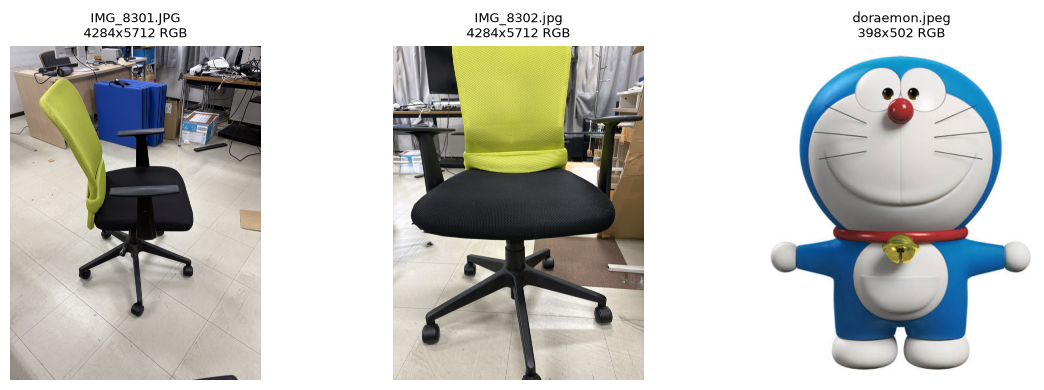

In [4]:
IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png", ".webp"}


def load_image(path: Path) -> Image.Image:
    img = ImageOps.exif_transpose(Image.open(path))
    return img if img.mode in ("RGB", "RGBA") else img.convert("RGB")


input_paths = sorted(p for p in INPUT_DIR.iterdir() if p.suffix.lower() in IMAGE_SUFFIXES)
assert input_paths, f"{INPUT_DIR} に画像がありません"
input_images = {p.name: load_image(p) for p in input_paths}

fig, axes = plt.subplots(1, len(input_images), figsize=(4 * len(input_images), 4), squeeze=False)
for ax, (name, img) in zip(axes[0], input_images.items()):
    ax.imshow(img)
    ax.set_title(f"{name}\n{img.size[0]}x{img.size[1]} {img.mode}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 5. パイプラインの読み込み

`TripoSplatPipeline`（`external/TripoSplat/triposplat.py`）に `device="mps"` を渡します。
内訳: DINOv3 ViT-H（画像特徴, bf16）/ FLUX.2 VAE encoder（bf16）/ BiRefNet（背景除去, fp16）/ Flow モデル（fp16）/ Gaussian デコーダ（fp16）。

In [5]:
from triposplat import TripoSplatPipeline

with timer() as t_load:
    pipe = TripoSplatPipeline(**{k: str(CKPT_DIR / f) for k, f in CKPT_FILES.items()}, device=str(DEVICE))

n_params = {name: sum(p.numel() for p in getattr(pipe, name).parameters()) / 1e6
            for name in ["dinov3", "vae_encoder", "rmbg", "flow_model", "decoder"]}
print(f"loaded in {t_load['sec']:.1f}s")
for name, n in n_params.items():
    print(f"  {name:12s} {n:8.1f} M params  dtype={next(getattr(pipe, name).parameters()).dtype}")

loaded in 5.0s
  dinov3          840.6 M params  dtype=torch.bfloat16
  vae_encoder      34.4 M params  dtype=torch.bfloat16
  rmbg            220.2 M params  dtype=torch.float16
  flow_model      370.5 M params  dtype=torch.float16
  decoder         288.1 M params  dtype=torch.float16


## 6. 1 枚の画像で段階的に実行

`TripoSplatPipeline.run()` の中身を段階ごとに分けて実行し、中間結果と所要時間を確認します（`run_gradio.py` と同じ分け方）。
同じ seed なら `pipe.run()` と同じ結果になります。

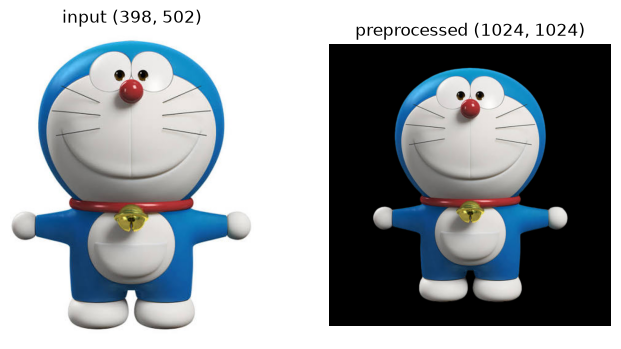

preprocess: 1.47s


In [6]:
sample_path = INPUT_DIR / SAMPLE_IMAGE
sample_image = input_images[SAMPLE_IMAGE]
timings = {}

gen = torch.Generator(device=DEVICE).manual_seed(SEED)

# (1) 背景除去 → 物体を中心に 1024x1024 へクロップ → 黒背景に合成
with timer() as t:
    prepared = pipe.preprocess_image(sample_image, erode_radius=ERODE_RADIUS)
timings["preprocess"] = t["sec"]

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(sample_image); axes[0].set_title(f"input {sample_image.size}")
axes[1].imshow(prepared);     axes[1].set_title(f"preprocessed {prepared.size}")
for ax in axes:
    ax.axis("off")
plt.show()
print(f"preprocess: {timings['preprocess']:.2f}s")

In [7]:
# (2) 画像エンコード: DINOv3 特徴 (feature1) と FLUX.2 VAE 潜在 (feature2)
with timer() as t:
    cond = pipe.encode_image(prepared, generator=gen)
timings["encode"] = t["sec"]
for k, v in cond.items():
    print(f"{k}: shape={tuple(v.shape)} dtype={v.dtype} device={v.device}  mean={v.float().mean():.3f} std={v.float().std():.3f}")
print(f"encode: {timings['encode']:.2f}s")

feature1: shape=(1, 4101, 1280) dtype=torch.float32 device=mps:0  mean=0.000 std=1.000
feature2: shape=(1, 4101, 128) dtype=torch.float32 device=mps:0  mean=-0.026 std=0.875
encode: 1.86s


In [8]:
# (3) Flow matching で 3D 潜在をサンプリング (Euler 法, CFG あり)
with timer() as t:
    out = pipe.sample_latent(cond, steps=STEPS, guidance_scale=GUIDANCE_SCALE, shift=SHIFT,
                             generator=gen, show_progress=True)
timings["sample"] = t["sec"]
for k, v in out.items():
    print(f"{k}: shape={tuple(v.shape)}  finite={torch.isfinite(v).all().item()}")
print(f"sample: {timings['sample']:.2f}s ({timings['sample'] / STEPS:.2f}s/step)")

Sampling:   0%|          | 0/20 [00:00<?, ?it/s]

Sampling:   5%|▌         | 1/20 [00:03<01:09,  3.66s/it]

Sampling:  10%|█         | 2/20 [00:11<01:45,  5.85s/it]

Sampling:  15%|█▌        | 3/20 [00:18<01:53,  6.66s/it]

Sampling:  20%|██        | 4/20 [00:26<01:52,  7.02s/it]

Sampling:  25%|██▌       | 5/20 [00:33<01:47,  7.18s/it]

... (13 outputs left out)

Sampling:  95%|█████████▌| 19/20 [02:16<00:07,  7.68s/it]

Sampling: 100%|██████████| 20/20 [02:24<00:00,  7.82s/it]

Sampling: 100%|██████████| 20/20 [02:24<00:00,  7.24s/it]

latent: shape=(1, 8192, 16)  finite=True
camera: shape=(1, 1, 5)  finite=True
sample: 149.08s (7.45s/step)


In [9]:
# (4) 潜在 → 3D Gaussians にデコード
with timer() as t:
    gaussian = pipe.decode_latent(out["latent"], num_gaussians=NUM_GAUSSIANS)
timings["decode"] = t["sec"]
timings["total"] = sum(timings.values())
print(f"decode: {timings['decode']:.2f}s  →  {gaussian.get_xyz.shape[0]:,} gaussians")
print(f"total : {timings['total']:.2f}s")

decode: 3.59s  →  262,144 gaussians
total : 156.01s


In [10]:
def save_outputs(gaussian, prepared, image_path: Path, timings: dict, params: dict) -> Path:
    """data/output/<画像名>/ に ply / splat / 前処理画像 / メタ情報を保存して ply のパスを返す。"""
    out_dir = OUTPUT_DIR / image_path.stem
    out_dir.mkdir(parents=True, exist_ok=True)
    n = gaussian.get_xyz.shape[0]
    ply_path, splat_path = out_dir / f"gaussians_{n}.ply", out_dir / f"gaussians_{n}.splat"
    gaussian.save_ply(str(ply_path))
    gaussian.save_splat(str(splat_path))
    prepared.save(out_dir / "preprocessed.png")
    meta = {
        "input": image_path.name,
        "device": str(DEVICE),
        "torch": torch.__version__,
        "num_gaussians": n,
        "params": params,
        "timings_sec": timings,
        "files": [ply_path.name, splat_path.name, "preprocessed.png"],
    }
    (out_dir / "meta.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False))
    return ply_path


PARAMS = dict(seed=SEED, steps=STEPS, guidance_scale=GUIDANCE_SCALE, shift=SHIFT, erode_radius=ERODE_RADIUS)
sample_ply = save_outputs(gaussian, prepared, sample_path, timings, PARAMS)
for f in sorted(sample_ply.parent.iterdir()):
    print(f"{f.stat().st_size / 1e6:7.2f} MB  {f.relative_to(PROJECT_ROOT)}")

  17.83 MB  data/output/doraemon/gaussians_262144.ply
   8.39 MB  data/output/doraemon/gaussians_262144.splat
   0.00 MB  data/output/doraemon/meta.json
   0.35 MB  data/output/doraemon/preprocessed.png


## 7. 簡易プレビューと統計量

ノートブック内で手早く確認するため、Gaussian の中心点を色 (SH の DC 成分) と不透明度つきで散布図にします。
座標はビューア (`viewer/index.html`) と同じ向き（+Y が上、正面が +Z）に揃えています。
楕円体としての正確な見た目はブラウザのビューアで確認してください。

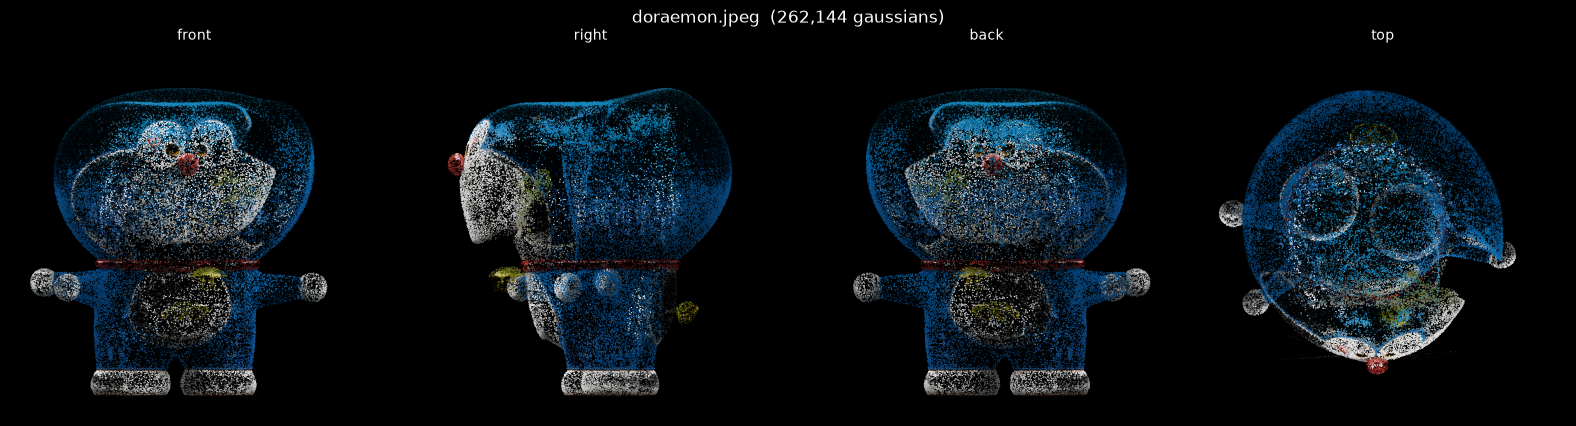

num gaussians : 262,144
bbox min      : [-0.499 -0.5   -0.438]
bbox max      : [0.457 0.534 0.433]
finite        : xyz=True opacity=True scale=True
opacity       : mean=0.490  >0.5: 47.4%
scale (max ax): median=0.0057  p99=0.0566


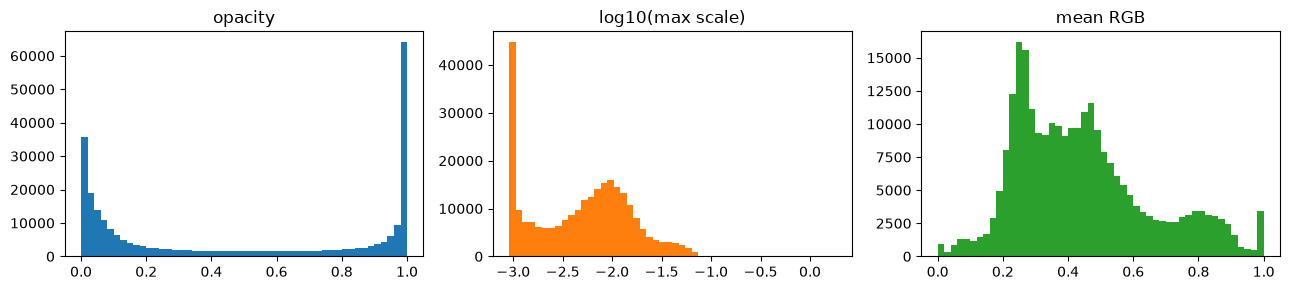

In [11]:
SH_C0 = 0.28209479177387814

# 画面の (横, 縦, 手前ほど大きい深度) を返す。xyz はビューア座標 (+Y up, 正面 +Z)。
VIEWS = {
    "front": lambda p: (p[:, 0], p[:, 1], p[:, 2]),
    "right": lambda p: (-p[:, 2], p[:, 1], p[:, 0]),
    "back":  lambda p: (-p[:, 0], p[:, 1], -p[:, 2]),
    "top":   lambda p: (p[:, 0], -p[:, 2], p[:, 1]),
}


def gaussian_to_numpy(g) -> dict:
    xyz = g.get_xyz.detach().float().cpu().numpy()
    # TripoSplat 内部座標 → ビューア座標: (x, y, z) → (y, z, x)
    #   (保存時の変換 Gaussian._DEFAULT_TRANSFORM と viewer の回転を合成したもの)
    return {
        "xyz": xyz[:, [1, 2, 0]],
        "rgb": np.clip(g._features_dc.detach().float().cpu().numpy()[:, 0, :] * SH_C0 + 0.5, 0, 1),
        "opacity": g.get_opacity.detach().float().cpu().numpy()[:, 0],
        "scale": g.get_scaling.detach().float().cpu().numpy(),
    }


def draw_view(ax, d: dict, view: str, max_points: int = 80000, seed: int = 0):
    n = len(d["xyz"])
    idx = np.random.default_rng(seed).choice(n, size=min(n, max_points), replace=False)
    u, v, depth = VIEWS[view](d["xyz"][idx])
    rgba = np.concatenate([d["rgb"][idx], d["opacity"][idx, None]], axis=1)
    order = np.argsort(depth)  # 奥から手前の順に描く
    ax.scatter(u[order], v[order], c=rgba[order], s=0.8, linewidths=0)
    lim = np.abs(d["xyz"]).max() * 1.05
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
    ax.set_aspect("equal")
    ax.set_facecolor("black")
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(view, color="white", fontsize=10)


def preview_gaussian(g, title: str = ""):
    d = gaussian_to_numpy(g)
    fig, axes = plt.subplots(1, len(VIEWS), figsize=(4 * len(VIEWS), 4.3), facecolor="black")
    for ax, view in zip(axes, VIEWS):
        draw_view(ax, d, view)
    fig.suptitle(title, color="white")
    plt.tight_layout()
    plt.show()


def gaussian_stats(g):
    d = gaussian_to_numpy(g)
    xyz, op, sc = d["xyz"], d["opacity"], d["scale"]
    print(f"num gaussians : {len(xyz):,}")
    print(f"bbox min      : {np.round(xyz.min(0), 3)}")
    print(f"bbox max      : {np.round(xyz.max(0), 3)}")
    print(f"finite        : xyz={np.isfinite(xyz).all()} opacity={np.isfinite(op).all()} scale={np.isfinite(sc).all()}")
    print(f"opacity       : mean={op.mean():.3f}  >0.5: {(op > 0.5).mean() * 100:.1f}%")
    print(f"scale (max ax): median={np.median(sc.max(1)):.4f}  p99={np.percentile(sc.max(1), 99):.4f}")
    fig, axes = plt.subplots(1, 3, figsize=(13, 3))
    axes[0].hist(op, bins=50, color="tab:blue");                     axes[0].set_title("opacity")
    axes[1].hist(np.log10(sc.max(1)), bins=50, color="tab:orange");  axes[1].set_title("log10(max scale)")
    axes[2].hist(d["rgb"].mean(1), bins=50, color="tab:green");      axes[2].set_title("mean RGB")
    plt.tight_layout()
    plt.show()


preview_gaussian(gaussian, f"{SAMPLE_IMAGE}  ({gaussian.get_xyz.shape[0]:,} gaussians)")
gaussian_stats(gaussian)

## 8. 全画像をまとめて処理

公式 API の `pipe.run()` で `data/input/` の残りの画像を処理します（`RUN_ALL_IMAGES = False` でスキップ）。

In [12]:
results = {SAMPLE_IMAGE: {"gaussian": gaussian, "prepared": prepared, "ply": sample_ply, "sec": timings["total"]}}

if RUN_ALL_IMAGES:
    for path in input_paths:
        if path.name in results:
            continue
        print(f"--- {path.name}")
        with timer() as t:
            g, prep = pipe.run(input_images[path.name], seed=SEED, steps=STEPS, guidance_scale=GUIDANCE_SCALE,
                               shift=SHIFT, num_gaussians=NUM_GAUSSIANS, erode_radius=ERODE_RADIUS,
                               show_progress=True)
        ply = save_outputs(g, prep, path, {"total": t["sec"]}, PARAMS)
        results[path.name] = {"gaussian": g, "prepared": prep, "ply": ply, "sec": t["sec"]}

print(f"{'image':20s} {'gaussians':>10s} {'time [s]':>9s}  output")
for name, r in results.items():
    print(f"{name:20s} {r['gaussian'].get_xyz.shape[0]:>10,} {r['sec']:>9.1f}  {r['ply'].relative_to(PROJECT_ROOT)}")

--- IMG_8301.JPG


Sampling:   0%|          | 0/20 [00:00<?, ?it/s]

Sampling:   5%|▌         | 1/20 [00:06<02:06,  6.68s/it]

Sampling:  10%|█         | 2/20 [00:15<02:18,  7.70s/it]

Sampling:  15%|█▌        | 3/20 [00:23<02:16,  8.03s/it]

Sampling:  20%|██        | 4/20 [00:32<02:11,  8.23s/it]

... (37 outputs left out)

Sampling:  95%|█████████▌| 19/20 [03:07<00:09,  9.72s/it]

Sampling: 100%|██████████| 20/20 [03:17<00:00,  9.82s/it]

Sampling: 100%|██████████| 20/20 [03:17<00:00,  9.89s/it]

image                 gaussians  time [s]  output
doraemon.jpeg           262,144     156.0  data/output/doraemon/gaussians_262144.ply
IMG_8301.JPG            262,144     191.6  data/output/IMG_8301/gaussians_262144.ply
IMG_8302.jpg            262,144     206.8  data/output/IMG_8302/gaussians_262144.ply


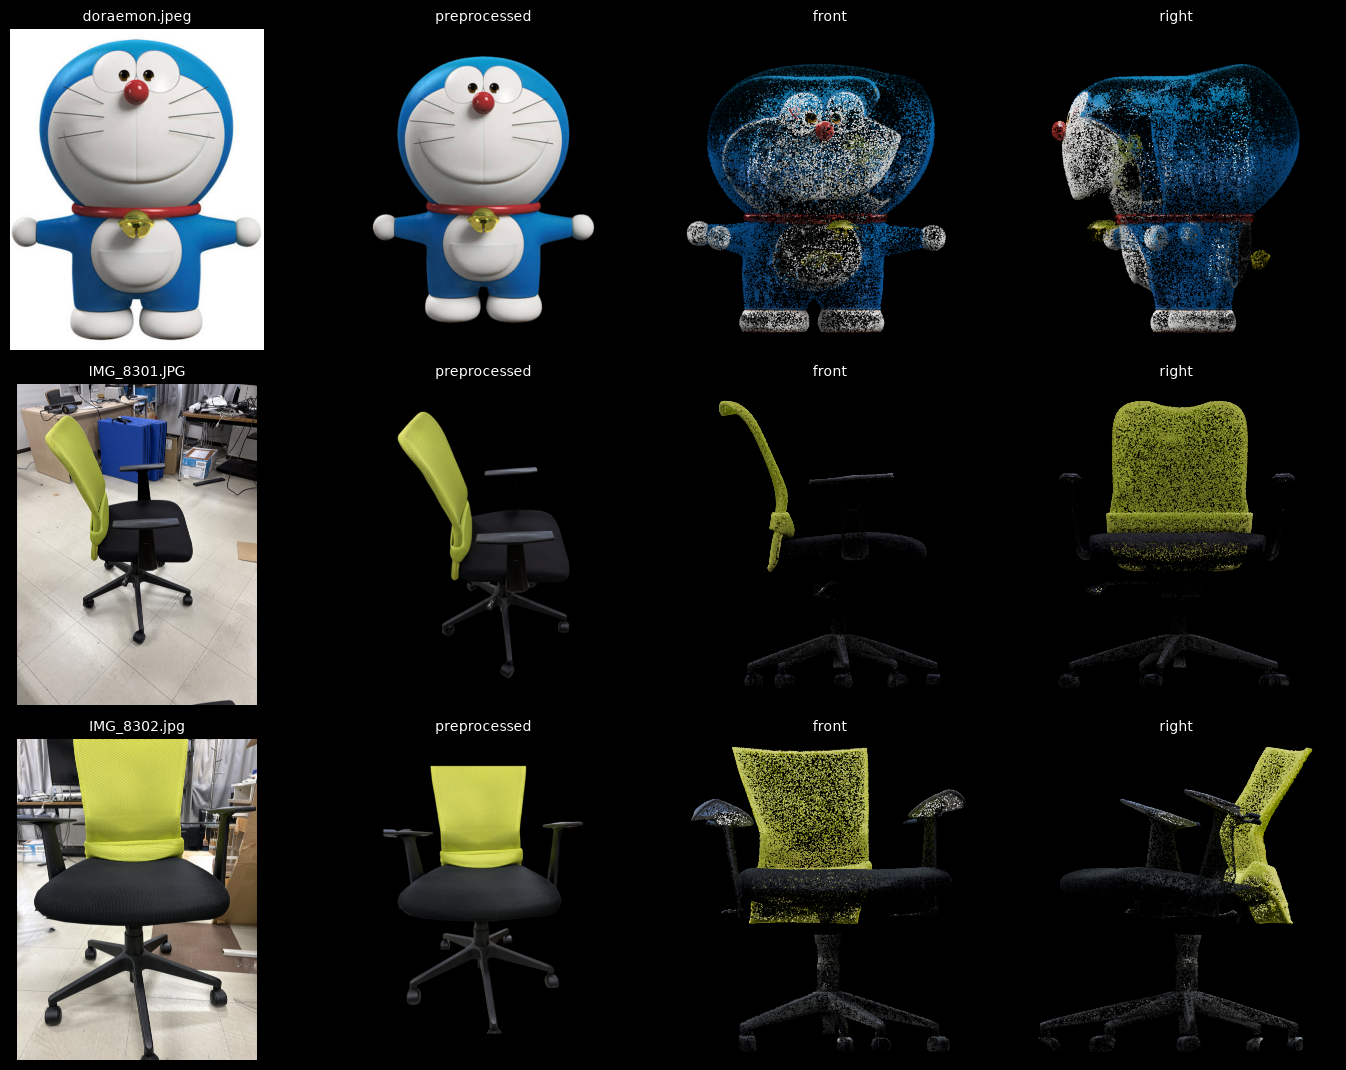

In [13]:
# 入力 / 前処理 / 正面 / 側面 を一覧表示
fig, axes = plt.subplots(len(results), 4, figsize=(14, 3.6 * len(results)), squeeze=False, facecolor="black")
for row, (name, r) in zip(axes, results.items()):
    row[0].imshow(input_images[name]); row[0].set_title(name, color="white", fontsize=10)
    row[1].imshow(r["prepared"]);      row[1].set_title("preprocessed", color="white", fontsize=10)
    for ax in row[:2]:
        ax.axis("off")
    d = gaussian_to_numpy(r["gaussian"])
    draw_view(row[2], d, "front")
    draw_view(row[3], d, "right")
plt.tight_layout()
plt.show()

## 9. ガウシアン数による比較

`num_gaussians` にリストを渡すと、Flow サンプリングは 1 回だけ行い、デコーダだけを各数で実行します。
数を減らすとファイルサイズと描画負荷が下がる代わりに細部が粗くなります。

4 densities in 284.6s (denoiser 1 回 + decoder 4 回)


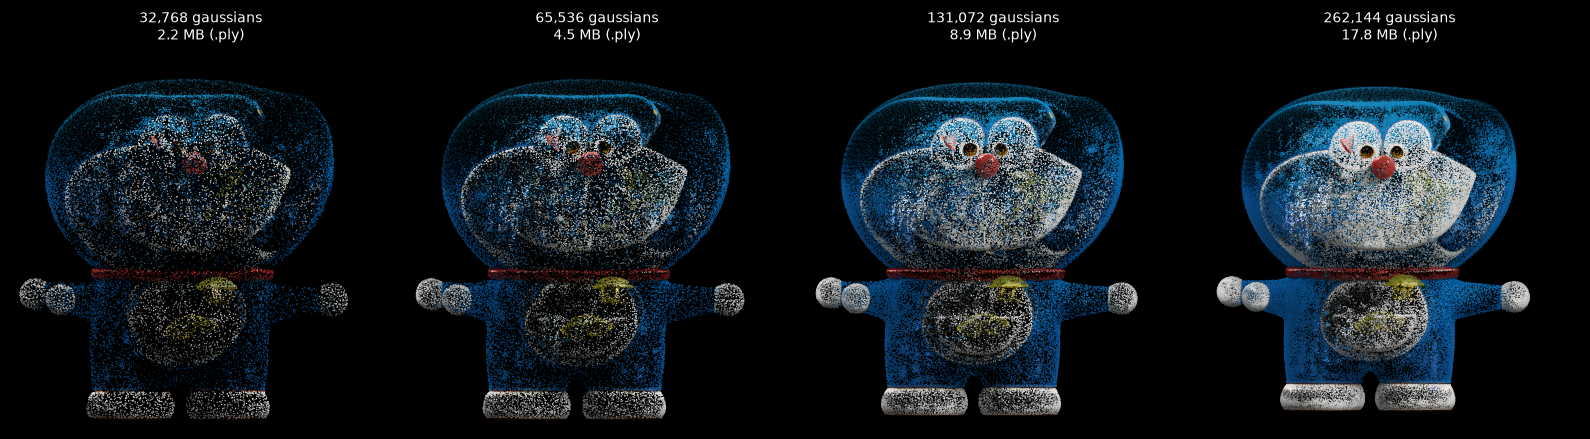

In [14]:
if RUN_DENSITY_COMPARISON:
    with timer() as t:
        density_gaussians, _ = pipe.run(sample_image, seed=SEED, steps=STEPS, guidance_scale=GUIDANCE_SCALE,
                                        shift=SHIFT, num_gaussians=DENSITY_COUNTS, erode_radius=ERODE_RADIUS)
    print(f"{len(DENSITY_COUNTS)} densities in {t['sec']:.1f}s (denoiser 1 回 + decoder {len(DENSITY_COUNTS)} 回)")

    fig, axes = plt.subplots(1, len(DENSITY_COUNTS), figsize=(4 * len(DENSITY_COUNTS), 4.3), facecolor="black")
    for ax, n, g in zip(axes, DENSITY_COUNTS, density_gaussians):
        ply = sample_ply.parent / f"gaussians_{n}.ply"
        g.save_ply(str(ply))
        draw_view(ax, gaussian_to_numpy(g), "front", max_points=n)
        ax.set_title(f"{n:,} gaussians\n{ply.stat().st_size / 1e6:.1f} MB (.ply)", color="white", fontsize=10)
    plt.tight_layout()
    plt.show()

## 10. ブラウザのビューアで表示

`viewer/view_splat.py` がローカルサーバ (`127.0.0.1`) を起動し、Spark.js で Gaussian Splatting として描画します。
左の一覧からモデルを切り替え、ドラッグで回転・スクロールでズームできます。
ターミナルから単体で起動する場合は次のコマンドです（Ctrl+C で終了）。

```bash
uv run python viewer/view_splat.py                                    # data/output の一覧
uv run python viewer/view_splat.py --file doraemon/gaussians_262144.ply
```

In [15]:
# 既に起動していれば止めてから起動し直す
viewer_proc = globals().get("viewer_proc")
if viewer_proc is not None and viewer_proc.poll() is None:
    viewer_proc.terminate()
    viewer_proc.wait()

if LAUNCH_VIEWER:
    viewer_proc = subprocess.Popen(
        [sys.executable, str(VIEWER_SCRIPT), "--file", sample_ply.relative_to(OUTPUT_DIR).as_posix()],
        stdout=subprocess.PIPE, text=True, start_new_session=True,
    )
    for line in viewer_proc.stdout:  # サーバの URL が出るまで待つ
        print(line, end="")
        if "open http" in line:
            break
else:
    print("LAUNCH_VIEWER=False のためスキップ:", f"uv run python viewer/view_splat.py --file {sample_ply.relative_to(OUTPUT_DIR)}")

LAUNCH_VIEWER=False のためスキップ: uv run python viewer/view_splat.py --file doraemon/gaussians_262144.ply


In [16]:
# ビューアを止める
if globals().get("viewer_proc") is not None and viewer_proc.poll() is None:
    viewer_proc.terminate()
    print("viewer stopped")